# CDMA / DSSS: pulling a signal out of the noise

A bit $b\in\{\pm1\}$, a code $c_k\in\{\pm1\}$, $N$ chips per bit. Received: $r_k = A\,b\,c_k + n_k$, $n_k\sim\mathcal N(0,\sigma^2)$.

Despreading:
$$z=\sum_k r_k c_k = A\,b\,N + \sum_k n_k c_k,\qquad \mathrm{Var}\Big(\sum n_k c_k\Big)=N\sigma^2$$

$$\mathrm{SNR}_\text{out}=\frac{(AN)^2}{N\sigma^2}=N\cdot\mathrm{SNR}_\text{chip}$$

**The signal grows as $N$, the noise only as $\sqrt N$.** Processing gain $G_p=10\log_{10}N$ dB.

All parameters are in the cell below; everything else is recomputed from them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
SNR_CHIP_DB = -15.0   # SNR per chip, dB (signal below the noise)
NBITS_LFSR = 10       # N = 2^10 - 1 = 1023, as in GPS C/A
JSR_DB = 20.0         # jammer power relative to the signal, dB

rng = np.random.default_rng(SEED)

## Primitives: m-sequence, Gold codes, spreading, channel

In [2]:
def mseq(taps, nbits, seed=1):
    """m-sequence from a Fibonacci LFSR, output in {+1,-1}, length 2^nbits-1."""
    state = [(seed >> i) & 1 for i in range(nbits)]
    out = []
    for _ in range(2**nbits - 1):
        out.append(state[-1])
        fb = 0
        for t in taps:
            fb ^= state[t - 1]
        state = [fb] + state[:-1]
    return 1 - 2 * np.array(out, dtype=float)

TAPS = {7: [7, 6], 10: [10, 3]}

def gold(shift, nbits=10):
    """Gold code from a preferred pair (GPS C/A polynomials: G1=[10,3], G2=[10,9,8,6,3,2])."""
    return mseq([10, 3], nbits) * np.roll(mseq([10, 9, 8, 6, 3, 2], nbits), shift)

def spread(bits, code):
    return np.repeat(bits, len(code)) * np.tile(code, len(bits))

def despread(rx, code):
    return (rx.reshape(-1, len(code)) * code).sum(axis=1)

def awgn(x, snr_db, rng, amp=1.0):
    sigma = amp / np.sqrt(10 ** (snr_db / 10))
    return x + sigma * rng.standard_normal(len(x)), sigma

code = mseq(TAPS[NBITS_LFSR], NBITS_LFSR)
N = len(code)
print(f"N = {N}, Gp = {10*np.log10(N):.1f} dB, SNR per chip = {SNR_CHIP_DB} dB "
      f"→ expected SNR after despreading ≈ {SNR_CHIP_DB + 10*np.log10(N):.1f} dB")

N = 1023, Gp = 30.1 dB, SNR per chip = -15.0 dB → expected SNR after despreading ≈ 15.1 dB


## 1. Time domain
Three bits, each smeared over $N$ chips. The chips are invisible in the received signal: the noise amplitude is ~5.6 times larger. Summing against the code recovers the sign.

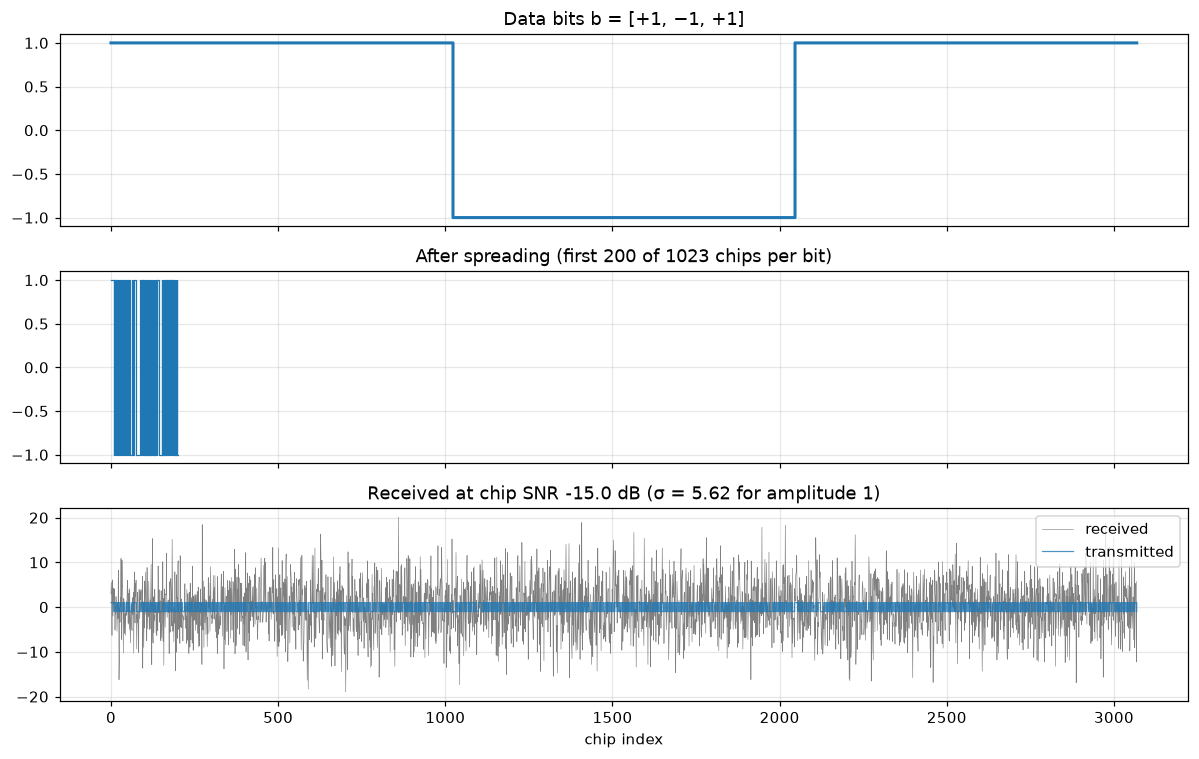

z     = [1334 -923 1108]   (expected ±N = ±1023, noise σ = √N·σ = 180)
b_hat = [ 1 -1  1]


In [3]:
bits = np.array([1.0, -1.0, 1.0])
tx = spread(bits, code)
rx, sigma = awgn(tx, SNR_CHIP_DB, rng)
z = despread(rx, code)

t = np.arange(3 * N)
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ax[0].step(t, np.repeat(bits, N), where="post", lw=2); ax[0].set_title("Data bits b = [+1, −1, +1]")
ax[1].step(t[:200], tx[:200], where="post", lw=0.8); ax[1].set_title(f"After spreading (first 200 of {N} chips per bit)")
ax[2].plot(t, rx, lw=0.4, color="gray", label="received")
ax[2].step(t, tx, where="post", lw=0.8, alpha=0.8, label="transmitted")
ax[2].set_title(f"Received at chip SNR {SNR_CHIP_DB} dB (σ = {sigma:.2f} for amplitude 1)")
ax[2].set_xlabel("chip index"); ax[2].legend(loc="upper right")
plt.tight_layout(); plt.show()

print("z     =", np.round(z).astype(int), f"  (expected ±N = ±{N}, noise σ = √N·σ = {np.sqrt(N)*sigma:.0f})")
print("b_hat =", np.sign(z).astype(int))

## 2. Correlation over code shift (acquisition)
Autocorrelation of an m-sequence: $R(0)=N$, $R(\tau\ne0)=-1$. The receiver doesn't know the code phase, so it tries every shift at once with an FFT (this is what GPS receivers do). The peak stands $\approx\sqrt{N\cdot\mathrm{SNR_{chip}}}$ σ above the noise.

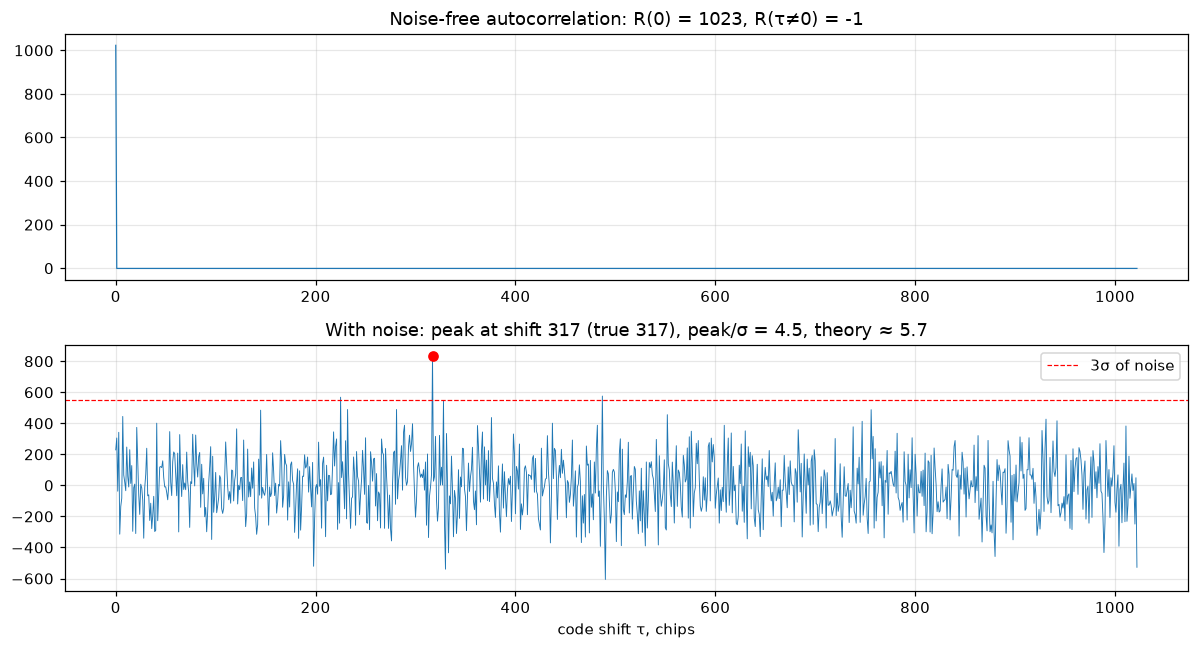

In [4]:
true_shift = 317
rx, _ = awgn(np.roll(code, true_shift), SNR_CHIP_DB, rng)
xcorr = lambda a, b: np.real(np.fft.ifft(np.fft.fft(a) * np.conj(np.fft.fft(b))))
corr, clean = xcorr(rx, code), xcorr(code, code)

pk = np.argmax(corr)
floor = np.std(np.delete(corr, pk))
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(clean, lw=0.8)
ax[0].set_title(f"Noise-free autocorrelation: R(0) = {clean[0]:.0f}, R(τ≠0) = {np.median(clean[1:]):.0f}")
ax[1].plot(corr, lw=0.6); ax[1].plot(pk, corr[pk], "ro")
ax[1].axhline(3 * floor, color="r", ls="--", lw=0.8, label="3σ of noise")
ax[1].set_title(f"With noise: peak at shift {pk} (true {true_shift}), peak/σ = {corr[pk]/floor:.1f}, "
                f"theory ≈ {np.sqrt(N * 10**(SNR_CHIP_DB/10)):.1f}")
ax[1].set_xlabel("code shift τ, chips"); ax[1].legend()
plt.tight_layout(); plt.show()

At −15 dB the peak is barely above 3σ. In practice acquisition accumulates several code periods (GPS: 1–20 ms coherently plus non-coherent accumulation).

## 3. Distribution of the decision statistic
Left: deciding from a single chip (almost a coin flip). Right: $z/N$, with mean $\pm1$ and a standard deviation $\sqrt N$ times smaller.

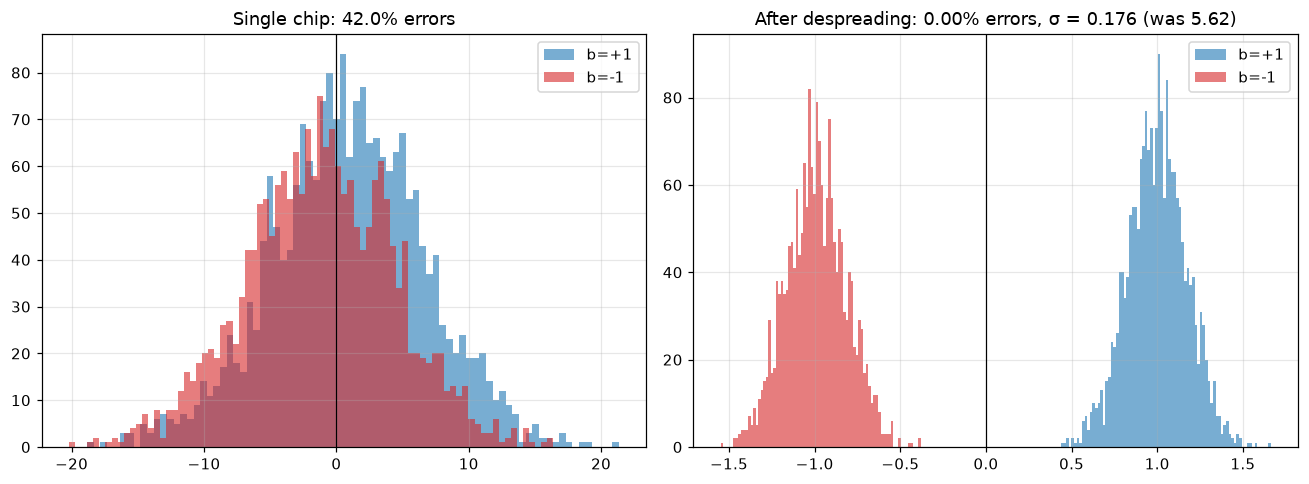

In [5]:
nb = 4000
bits = rng.choice([-1.0, 1.0], nb)
rx, sigma = awgn(spread(bits, code), SNR_CHIP_DB, rng)
one_chip = rx.reshape(-1, N)[:, 0] * code[0]
zn = despread(rx, code) / N

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for b, c in [(1, "C0"), (-1, "C3")]:
    ax[0].hist(one_chip[bits == b], 80, alpha=0.6, color=c, label=f"b={b:+d}")
    ax[1].hist(zn[bits == b], 80, alpha=0.6, color=c, label=f"b={b:+d}")
ax[0].set_title(f"Single chip: {np.mean(np.sign(one_chip) != bits):.1%} errors")
ax[1].set_title(f"After despreading: {np.mean(np.sign(zn) != bits):.2%} errors, σ = {sigma/np.sqrt(N):.3f} (was {sigma:.2f})")
for a in ax: a.axvline(0, color="k", lw=0.8); a.legend()
plt.tight_layout(); plt.show()

## 4. Narrowband interference (jammer)
A tone `JSR_DB` dB stronger than the signal. When the receiver multiplies by the code, our own signal **collapses** into the bit bandwidth while the jammer is **spread** over the whole code bandwidth. After low-pass filtering (summing over a bit), only ~$1/N$ of the jammer remains.

All spectra are normalized to the same reference: the jammer peak before despreading.

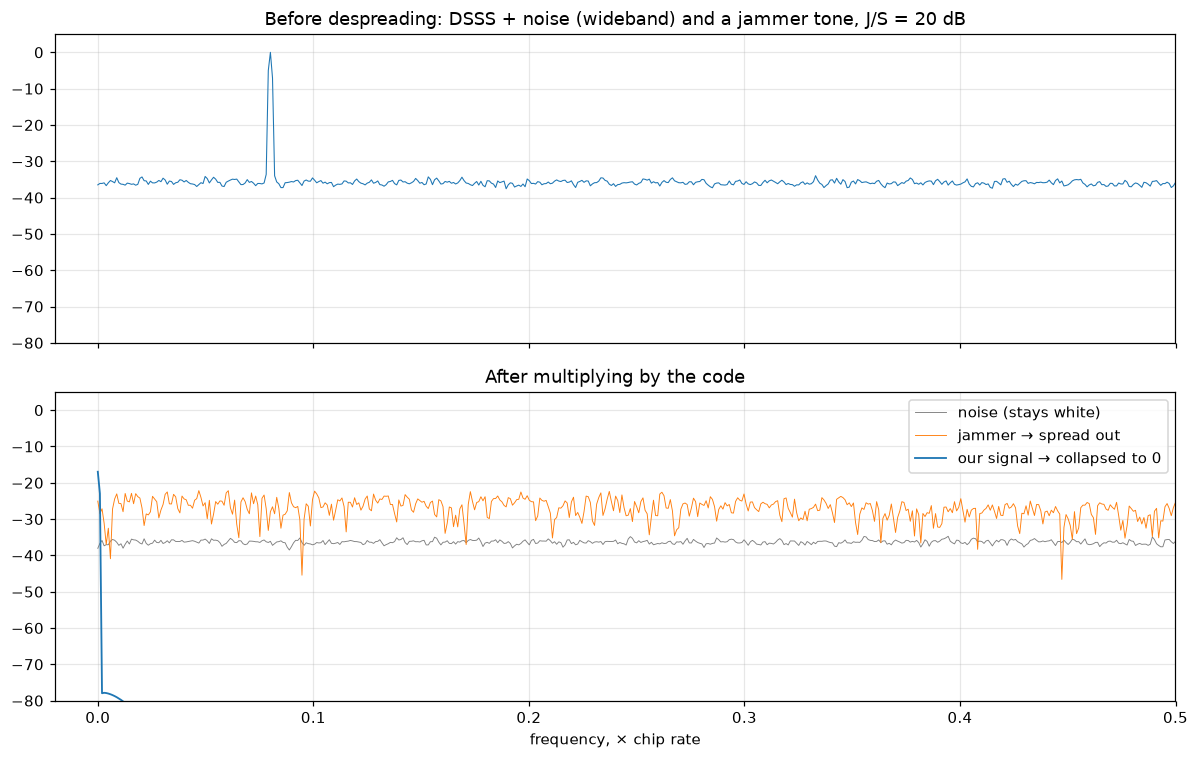

J/S at the input: 20.0 dB → after the integrator: -7.8 dB (suppression 27.8 dB, theory 10·log10(N) = 30.1)
BER at J/S = 20 dB after despreading: 0.000


In [6]:
nb, sps = 64, 4
bits = rng.choice([-1.0, 1.0], nb)
tx = np.repeat(spread(bits, code), sps)
n = np.arange(len(tx))
J = np.sqrt(2 * 10 ** (JSR_DB / 10)) * np.cos(2 * np.pi * 0.02 * n)
noise = (1 / np.sqrt(10 ** (SNR_CHIP_DB / 10))) * rng.standard_normal(len(tx))
code_up = np.tile(np.repeat(code, sps), nb)

def psd(x, seg=4096):
    x = x[: len(x) // seg * seg].reshape(-1, seg) * np.hanning(seg)
    return np.fft.rfftfreq(seg) * sps, np.mean(np.abs(np.fft.rfft(x, axis=1)) ** 2, axis=0)

f, P_rx = psd(tx + J + noise)
ref = P_rx.max()
dB = lambda P: 10 * np.log10(P / ref + 1e-20)
_, P_sig = psd(tx * code_up); _, P_j = psd(J * code_up); _, P_n = psd(noise * code_up)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(f, dB(P_rx), lw=0.7)
ax[0].set_title(f"Before despreading: DSSS + noise (wideband) and a jammer tone, J/S = {JSR_DB:.0f} dB")
ax[1].plot(f, dB(P_n), lw=0.6, color="gray", label="noise (stays white)")
ax[1].plot(f, dB(P_j), lw=0.6, color="C1", label="jammer → spread out")
ax[1].plot(f, dB(P_sig), lw=1.2, color="C0", label="our signal → collapsed to 0")
ax[1].set_title("After multiplying by the code")
ax[1].set_xlabel("frequency, × chip rate"); ax[1].legend(loc="upper right")
for a in ax: a.set_ylim(-80, 5)
ax[1].set_xlim(-0.02, 0.5)
plt.tight_layout(); plt.show()

z = despread((tx + J + noise)[::sps], code)
zJ = despread(J[::sps], code) / N          # jammer contribution to z/N (the signal contributes ±1)
print(f"J/S at the input: {JSR_DB:.1f} dB → after the integrator: {10*np.log10(np.mean(zJ**2)):.1f} dB "
      f"(suppression {JSR_DB - 10*np.log10(np.mean(zJ**2)):.1f} dB, theory 10·log10(N) = {10*np.log10(N):.1f})")
print(f"BER at J/S = {JSR_DB:.0f} dB after despreading: {np.mean(np.sign(z) != bits):.3f}")

## 5. Two users in one band
Gold codes (as in GPS C/A) have cross-correlation $|R_{12}|\le 65 \ll N=1023$. Each receiver sees the other user's signal as extra noise.

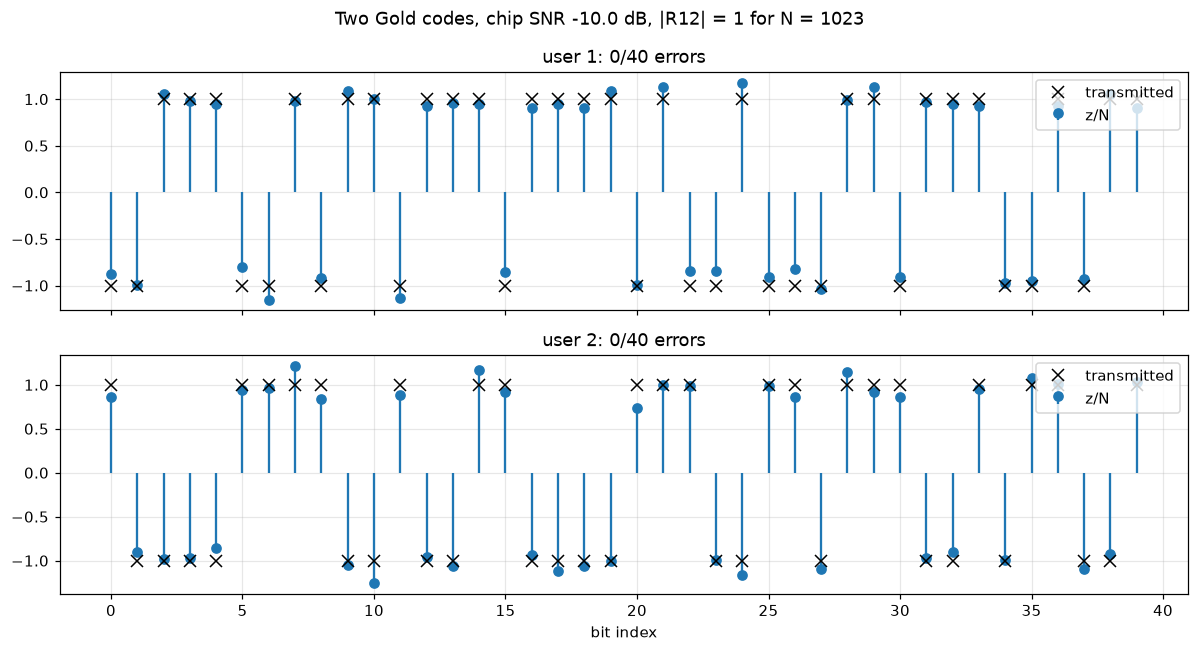

In [7]:
c1, c2 = gold(5), gold(200)
nb = 40
b1, b2 = rng.choice([-1.0, 1.0], nb), rng.choice([-1.0, 1.0], nb)
snr = SNR_CHIP_DB + 5
rx, _ = awgn(spread(b1, c1) + spread(b2, c2), snr, rng)
z1, z2 = despread(rx, c1) / N, despread(rx, c2) / N

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, zz, b, name in [(ax[0], z1, b1, "user 1"), (ax[1], z2, b2, "user 2")]:
    a.stem(zz, basefmt=" ", label="z/N"); a.plot(b, "kx", ms=8, label="transmitted")
    a.set_title(f"{name}: {int(np.sum(np.sign(zz) != b))}/{nb} errors"); a.legend(loc="upper right")
ax[1].set_xlabel("bit index")
fig.suptitle(f"Two Gold codes, chip SNR {snr} dB, |R12| = {abs(np.sum(c1*c2)):.0f} for N = {N}")
plt.tight_layout(); plt.show()

## 6. BER: an important caveat
$E_b/N_0 = N\cdot\mathrm{SNR_{chip}}/2$ (real-valued noise: $N_0/2=\sigma^2$). Against white noise CDMA **gains nothing**: the curve is exactly plain BPSK. The benefit is that the per-chip SNR is deeply negative: the signal is invisible in the spectrum, and narrowband interference is suppressed by a factor of $N$.

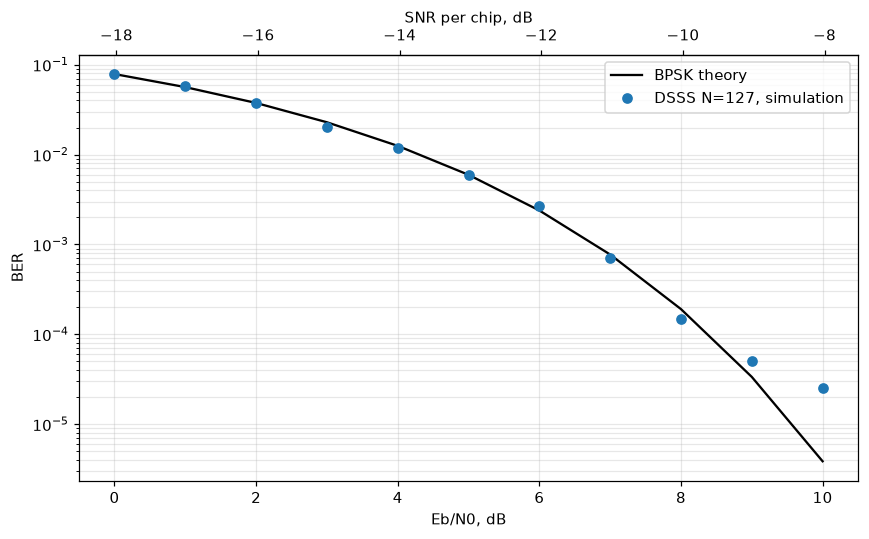

In [8]:
code127 = mseq(TAPS[7], 7)  # shorter = faster; BER doesn't depend on N
N7 = len(code127)
ebn0 = np.arange(0, 11)
sim = []
for e in ebn0:
    errs = 0
    for _ in range(10):
        b = rng.choice([-1.0, 1.0], 2000)
        rx, _ = awgn(spread(b, code127), e + 10*np.log10(2) - 10 * np.log10(N7), rng)
        errs += np.sum(np.sign(despread(rx, code127)) != b)
    sim.append(max(errs, 0.5) / 20000)

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(ebn0, 0.5 * erfc(np.sqrt(10 ** (ebn0 / 10))), "k-", label="BPSK theory")
ax.semilogy(ebn0, sim, "o", label=f"DSSS N={N7}, simulation")
top = ax.secondary_xaxis("top", functions=(lambda x: x + 10*np.log10(2) - 10*np.log10(N7), lambda x: x - 10*np.log10(2) + 10*np.log10(N7)))
top.set_xlabel("SNR per chip, dB")
ax.set_xlabel("Eb/N0, dB"); ax.set_ylabel("BER"); ax.grid(which="both", alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Things to try
- `SNR_CHIP_DB` → −20…−25 dB: with N=1023, errors start to appear around −25 dB
- `NBITS_LFSR = 7` (N=127): 21 dB of gain instead of 30, and every section gets visibly worse
- `JSR_DB` → 30–35 dB: the jammer starts to break through; the limit is ≈ Gp minus the Eb/N0 margin you need